# Environment Setup & Project Paths

In [1]:
import pandas as pd
import numpy as np
from pathlib import Path

# Resolve project paths dynamically regardless of where Jupyter is launched
PROJECT_ROOT = Path.cwd()
if PROJECT_ROOT.name == "notebooks":
    PROJECT_ROOT = PROJECT_ROOT.parent

RAW_DATA_PATH = PROJECT_ROOT / "data" / "raw"
PROCESSED_DATA_PATH = PROJECT_ROOT / "data" / "processed"

# Ensure target directory exists
PROCESSED_DATA_PATH.mkdir(parents=True, exist_ok=True)

print(f"Project Root:    {PROJECT_ROOT}")
print(f"Raw Data Path:   {RAW_DATA_PATH}")
print(f"Processed Path:  {PROCESSED_DATA_PATH}")

Project Root:    c:\Users\zaidz\Desktop\DATA_P1
Raw Data Path:   c:\Users\zaidz\Desktop\DATA_P1\data\raw
Processed Path:  c:\Users\zaidz\Desktop\DATA_P1\data\processed


# clean Customers 

Convert Birthday to datetime64[ns].

Impute the 10 missing State Code values by looking up the existing mapping from the State column.

Strip leading/trailing whitespaces across all categorical fields.

Compute customer age and categorize into standard demographic brackets (<25, 25-34, 35-49, 50-64, 65+)

In [3]:
print("--- Processing: Customers ---")
customers = pd.read_csv(RAW_DATA_PATH / "Customers.csv", encoding="cp1252")

# 1. Clean string fields
str_cols = ["Name", "City", "State Code", "State", "Zip Code", "Country", "Continent"]
for col in str_cols:
    customers[col] = customers[col].astype(str).str.strip()

# 2. Impute missing State Code using the State -> State Code mapping
state_code_map = (
    customers[customers["State Code"] != "nan"]
    .groupby("State")["State Code"]
    .agg(lambda x: x.mode().iloc[0] if not x.mode().empty else "Unknown")
    .to_dict()
)
customers["State Code"] = customers["State Code"].replace("nan", np.nan)
customers["State Code"] = customers["State Code"].fillna(customers["State"].map(state_code_map)).fillna("Unknown")

# 3. Parse Birthday
customers["Birthday"] = pd.to_datetime(customers["Birthday"], format="%m/%d/%Y", errors="coerce")

# 4. Feature Engineering: Reference Age (using 2021 as dataset reference year)
ref_year = 2021
customers["Age"] = ref_year - customers["Birthday"].dt.year
customers["Age_Group"] = pd.cut(
    customers["Age"],
    bins=[0, 25, 35, 50, 65, 120],
    labels=["<25", "25-34", "35-49", "50-64", "65+"],
    right=False
)

# 5. Export cleaned version
output_file = PROCESSED_DATA_PATH / "customers_cleaned.csv"
customers.to_csv(output_file, index=False)
print(f"Saved: {output_file.name} | Shape: {customers.shape} | Nulls remaining: {customers.isnull().sum().sum()}")
customers.head(3)

--- Processing: Customers ---
Saved: customers_cleaned.csv | Shape: (15266, 12) | Nulls remaining: 0


,CustomerKey,Gender,Name,City,State Code,State,Zip Code,Country,Continent,Birthday,Age,Age_Group
0,301,Female,Lilly Harding,WANDEARAH EAST,SA,South Australia,5523,Australia,Australia,1939-07-03,82,65+
1,325,Female,Madison Hull,MOUNT BUDD,WA,Western Australia,6522,Australia,Australia,1979-09-27,42,35-49
2,554,Female,Claire Ferres,WINJALLOK,VIC,Victoria,3380,Australia,Australia,1947-05-26,74,65+


# Clean Products 


Unit Cost USD and Unit Price USD contain currency symbols ($), commas, and trailing whitespace. Clean and cast to float64.

Engineer Unit_Margin_USD and Unit_Margin_Pct for SKU profitability analysis.

Verify that Unit Price USD >= Unit Cost USD to flag any loss-making catalog items.

In [4]:
print("--- Processing: Products ---")
products = pd.read_csv(RAW_DATA_PATH / "Products.csv", encoding="cp1252")

# 1. Strip string columns
for col in ["Product Name", "Brand", "Color", "Subcategory", "Category"]:
    products[col] = products[col].astype(str).str.strip()

# 2. Clean Currency Strings -> float64
price_cols = ["Unit Cost USD", "Unit Price USD"]
for col in price_cols:
    products[col] = (
        products[col]
        .astype(str)
        .str.replace("$", "", regex=False)
        .str.replace(",", "", regex=False)
        .str.strip()
        .astype(float)
    )

# 3. Feature Engineering: Margins
products["Unit_Margin_USD"] = (products["Unit Price USD"] - products["Unit Cost USD"]).round(2)
products["Unit_Margin_Pct"] = (
    (products["Unit_Margin_USD"] / products["Unit Price USD"]) * 100
).round(2)

# 4. Sanity Check
negative_margins = (products["Unit_Margin_USD"] < 0).sum()
print(f"Products with negative margin: {negative_margins}")

# 5. Export cleaned version
output_file = PROCESSED_DATA_PATH / "products_cleaned.csv"
products.to_csv(output_file, index=False)
print(f"Saved: {output_file.name} | Shape: {products.shape}")
products.head(3)

--- Processing: Products ---
Products with negative margin: 0
Saved: products_cleaned.csv | Shape: (2517, 12)


,ProductKey,Product Name,Brand,Color,Unit Cost USD,Unit Price USD,SubcategoryKey,Subcategory,CategoryKey,Category,Unit_Margin_USD,Unit_Margin_Pct
0,1,Contoso 512MB MP3 Player E51 Silver,Contoso,Silver,6.62,12.99,101,MP4&MP3,1,Audio,6.37,49.04
1,2,Contoso 512MB MP3 Player E51 Blue,Contoso,Blue,6.62,12.99,101,MP4&MP3,1,Audio,6.37,49.04
2,3,Contoso 1G MP3 Player E100 White,Contoso,White,7.40,14.52,101,MP4&MP3,1,Audio,7.12,49.04


# Clean Stores


Impute the 1 missing value in Square Meters using the median square footage of stores in the same country.

Parse Open Date into datetime64[ns].

Conformed Dimension Best Practice: Add a synthetic record for StoreKey = 0 ("Online Store", 0 sq meters). This ensures that when building your PostgreSQL star schema or Power BI relationship with Sales.StoreKey, foreign key joins never drop online transactions.

In [5]:
print("--- Processing: Stores ---")
stores = pd.read_csv(RAW_DATA_PATH / "Stores.csv", encoding="cp1252")

# 1. Strip strings
for col in ["Country", "State"]:
    stores[col] = stores[col].astype(str).str.strip()

# 2. Parse Open Date
stores["Open Date"] = pd.to_datetime(stores["Open Date"], format="%m/%d/%Y", errors="coerce")

# 3. Impute missing Square Meters with country median
country_medians = stores.groupby("Country")["Square Meters"].transform("median")
stores["Square Meters"] = stores["Square Meters"].fillna(country_medians)

# 4. Conformed Dimension: Ensure StoreKey = 0 (Online Store) is represented
if 0 not in stores["StoreKey"].values:
    online_store = pd.DataFrame([{
        "StoreKey": 0,
        "Country": "Online",
        "State": "Online",
        "Square Meters": 0.0,
        "Open Date": pd.to_datetime("2015-01-01")
    }])
    stores = pd.concat([online_store, stores], ignore_index=True)
    print("Added StoreKey = 0 (Online Store) for relational integrity.")

# 5. Channel Indicator
stores["Store_Type"] = np.where(stores["StoreKey"] == 0, "Online", "Physical Retail")

# 6. Export cleaned version
output_file = PROCESSED_DATA_PATH / "stores_cleaned.csv"
stores.to_csv(output_file, index=False)
print(f"Saved: {output_file.name} | Shape: {stores.shape} | Nulls: {stores.isnull().sum().sum()}")
stores.head(3)

--- Processing: Stores ---
Saved: stores_cleaned.csv | Shape: (67, 6) | Nulls: 1


,StoreKey,Country,State,Square Meters,Open Date,Store_Type
0,1,Australia,Australian Capital Territory,595.0,2008-01-01,Physical Retail
1,2,Australia,Northern Territory,665.0,2008-01-12,Physical Retail
2,3,Australia,South Australia,2000.0,2012-01-07,Physical Retail


# Clean Exchange_Rates 

Parse Date to datetime64[ns].

Standardize Currency codes to uppercase.

Ensure uniqueness across ['Date', 'Currency'].

In [6]:
print("--- Processing: Exchange Rates ---")
exchange = pd.read_csv(RAW_DATA_PATH / "Exchange_Rates.csv", encoding="cp1252")

# 1. Parse Date and standardize Currency
exchange["Date"] = pd.to_datetime(exchange["Date"], format="%m/%d/%Y", errors="coerce")
exchange["Currency"] = exchange["Currency"].astype(str).str.strip().str.upper()
exchange["Exchange"] = exchange["Exchange"].astype(float)

# 2. Check for duplicate date-currency pairs
duplicates = exchange.duplicated(subset=["Date", "Currency"]).sum()
if duplicates > 0:
    exchange = exchange.drop_duplicates(subset=["Date", "Currency"], keep="first")
    print(f"Removed {duplicates} duplicate exchange rate entries.")

# 3. Export cleaned version
output_file = PROCESSED_DATA_PATH / "exchange_rates_cleaned.csv"
exchange.to_csv(output_file, index=False)
print(f"Saved: {output_file.name} | Shape: {exchange.shape}")
exchange.head(3)

--- Processing: Exchange Rates ---
Saved: exchange_rates_cleaned.csv | Shape: (11215, 3)


,Date,Currency,Exchange
0,2015-01-01,USD,1.0000
1,2015-01-01,CAD,1.1583
2,2015-01-01,AUD,1.2214


# Clean Sales

Parse Order Date and Delivery Date.

Do not drop null delivery dates: Keep them as NaT (Not-a-Time) since physical store orders are fulfilled in person.

Engineer Channel (Online vs In-Store) and Delivery_Days = (Delivery Date - Order Date).dt.days (only valid for Online).

Validate that Quantity > 0 and that Delivery Date >= Order Date.

In [7]:
print("--- Processing: Sales ---")
sales = pd.read_csv(RAW_DATA_PATH / "Sales.csv", encoding="cp1252")

# 1. Parse Dates
sales["Order Date"] = pd.to_datetime(sales["Order Date"], format="%m/%d/%Y", errors="coerce")
sales["Delivery Date"] = pd.to_datetime(sales["Delivery Date"], format="%m/%d/%Y", errors="coerce")

# 2. Standardize Currency Code
sales["Currency Code"] = sales["Currency Code"].astype(str).str.strip().str.upper()

# 3. Channel & Logistics Feature Engineering
sales["Channel"] = np.where(sales["StoreKey"] == 0, "Online", "In-Store")
sales["Delivery_Days"] = (sales["Delivery Date"] - sales["Order Date"]).dt.days

# 4. Data Quality Check: Delivery should not happen before Order
invalid_delivery = (sales["Delivery_Days"] < 0).sum()
print(f"Anomalous orders (Delivery before Order Date): {invalid_delivery}")

# 5. Export cleaned version
output_file = PROCESSED_DATA_PATH / "sales_cleaned.csv"
sales.to_csv(output_file, index=False)
print(f"Saved: {output_file.name} | Shape: {sales.shape}")
sales.head(3)

--- Processing: Sales ---
Anomalous orders (Delivery before Order Date): 0
Saved: sales_cleaned.csv | Shape: (62884, 11)


,Order Number,Line Item,Order Date,Delivery Date,CustomerKey,StoreKey,ProductKey,Quantity,Currency Code,Channel,Delivery_Days
0,366000,1,2016-01-01,NaT,265598,10,1304,1,CAD,In-Store,NaN
1,366001,1,2016-01-01,2016-01-13,1269051,0,1048,2,USD,Online,12.0
2,366001,2,2016-01-01,2016-01-13,1269051,0,2007,1,USD,Online,12.0


# Pipeline Verification Summary

In [8]:
print("\n" + "=" * 60)
print("PROCESSED DATA DIRECTORY AUDIT")
print("=" * 60)

for file in sorted(PROCESSED_DATA_PATH.glob("*.csv")):
    df = pd.read_csv(file, nrows=5)
    row_count = sum(1 for _ in open(file, encoding="utf-8")) - 1
    file_size_kb = file.stat().st_size / 1024
    print(f"✓ {file.name:<28} | Rows: {row_count:>7,d} | Cols: {len(df.columns):>2} | Size: {file_size_kb:>7.1f} KB")

print("\nAll 5 datasets cleaned and saved successfully into 'data/processed/'!")



PROCESSED DATA DIRECTORY AUDIT
✓ customers_cleaned.csv        | Rows:  15,266 | Cols: 12 | Size:  1535.2 KB
✓ exchange_rates_cleaned.csv   | Rows:  11,215 | Cols:  3 | Size:   244.4 KB
✓ products_cleaned.csv         | Rows:   2,517 | Cols: 12 | Size:   310.9 KB
✓ sales_cleaned.csv            | Rows:  62,884 | Cols: 11 | Size:  3434.8 KB
✓ stores_cleaned.csv           | Rows:      67 | Cols:  6 | Size:     4.0 KB

All 5 datasets cleaned and saved successfully into 'data/processed/'!


# Integrate the Analytical Master Table

In [9]:
print("--- Building Unified Analytical Master Table ---")

# 1. Load the cleaned datasets
sales = pd.read_csv(PROCESSED_DATA_PATH / "sales_cleaned.csv", parse_dates=["Order Date", "Delivery Date"])
products = pd.read_csv(PROCESSED_DATA_PATH / "products_cleaned.csv")
customers = pd.read_csv(PROCESSED_DATA_PATH / "customers_cleaned.csv", parse_dates=["Birthday"])
stores = pd.read_csv(PROCESSED_DATA_PATH / "stores_cleaned.csv", parse_dates=["Open Date"])
exchange = pd.read_csv(PROCESSED_DATA_PATH / "exchange_rates_cleaned.csv", parse_dates=["Date"])

# 2. Join Products
master = sales.merge(
    products[[
        "ProductKey", "Product Name", "Brand", "Color", 
        "Unit Cost USD", "Unit Price USD", "Subcategory", "Category"
    ]],
    on="ProductKey",
    how="left"
)

# 3. Join Customers
master = master.merge(
    customers[[
        "CustomerKey", "Gender", "Name", "City", "State", 
        "Country", "Continent", "Age", "Age_Group"
    ]].rename(columns={"Country": "Customer_Country", "State": "Customer_State"}),
    on="CustomerKey",
    how="left"
)

# 4. Join Stores
master = master.merge(
    stores[[
        "StoreKey", "Country", "State", "Square Meters", "Store_Type"
    ]].rename(columns={"Country": "Store_Country", "State": "Store_State"}),
    on="StoreKey",
    how="left"
)

# 5. Join Exchange Rates on (Order Date == Date) and (Currency Code == Currency)
master = master.merge(
    exchange.rename(columns={"Date": "Order Date", "Currency": "Currency Code"}),
    on=["Order Date", "Currency Code"],
    how="left"
)

# Impute exchange rate = 1.0 if USD or missing
master["Exchange"] = master["Exchange"].fillna(1.0)

# 6. Core Financial Calculations (pegged to USD)
master["Revenue_USD"] = (master["Quantity"] * master["Unit Price USD"]).round(2)
master["Cost_USD"] = (master["Quantity"] * master["Unit Cost USD"]).round(2)
master["Profit_USD"] = (master["Revenue_USD"] - master["Cost_USD"]).round(2)
master["Profit_Margin_Pct"] = ((master["Profit_USD"] / master["Revenue_USD"]) * 100).round(2)

# Local Currency Normalization Check
master["Local_Revenue"] = (master["Revenue_USD"] * master["Exchange"]).round(2)

# 7. Add temporal helper columns for time-series analysis
master["Order_Year"] = master["Order Date"].dt.year
master["Order_YearMonth"] = master["Order Date"].dt.to_period("M").astype(str)
master["Order_Quarter"] = master["Order Date"].dt.to_period("Q").astype(str)
master["Order_DayOfWeek"] = master["Order Date"].dt.day_name()

# 8. Export Master File
master_path = PROCESSED_DATA_PATH / "sales_master_analytical.csv"
master.to_csv(master_path, index=False)

print(f"Master Analytical Dataset Created Successfully!")
print(f"File Path: {master_path}")
print(f"Total Rows: {len(master):,d} | Columns: {len(master.columns)}")

--- Building Unified Analytical Master Table ---
Master Analytical Dataset Created Successfully!
File Path: c:\Users\zaidz\Desktop\DATA_P1\data\processed\sales_master_analytical.csv
Total Rows: 62,884 | Columns: 40


## High-Level Portfolio Health Check (Executive KPIs)

In [10]:
total_revenue = master["Revenue_USD"].sum()
total_profit = master["Profit_USD"].sum()
overall_margin = (total_profit / total_revenue) * 100
total_orders = master["Order Number"].nunique()
total_units = master["Quantity"].sum()
avg_order_val = total_revenue / total_orders

print("=" * 50)
print("EXECUTIVE KPI SUMMARY")
print("=" * 50)
print(f"Total Net Revenue:     ${total_revenue:,.2f}")
print(f"Total Net Profit:      ${total_profit:,.2f}")
print(f"Gross Margin:          {overall_margin:.2f}%")
print(f"Total Orders:          {total_orders:,d}")
print(f"Total Units Sold:      {total_units:,d}")
print(f"Average Order Value:   ${avg_order_val:,.2f}")
print(f"Date Range:            {master['Order Date'].min().date()} to {master['Order Date'].max().date()}")
print("=" * 50)

EXECUTIVE KPI SUMMARY
Total Net Revenue:     $55,755,479.59
Total Net Profit:      $32,662,688.38
Gross Margin:          58.58%
Total Orders:          26,326
Total Units Sold:      197,757
Average Order Value:   $2,117.89
Date Range:            2016-01-01 to 2021-02-20


## Baseline Visual EDA

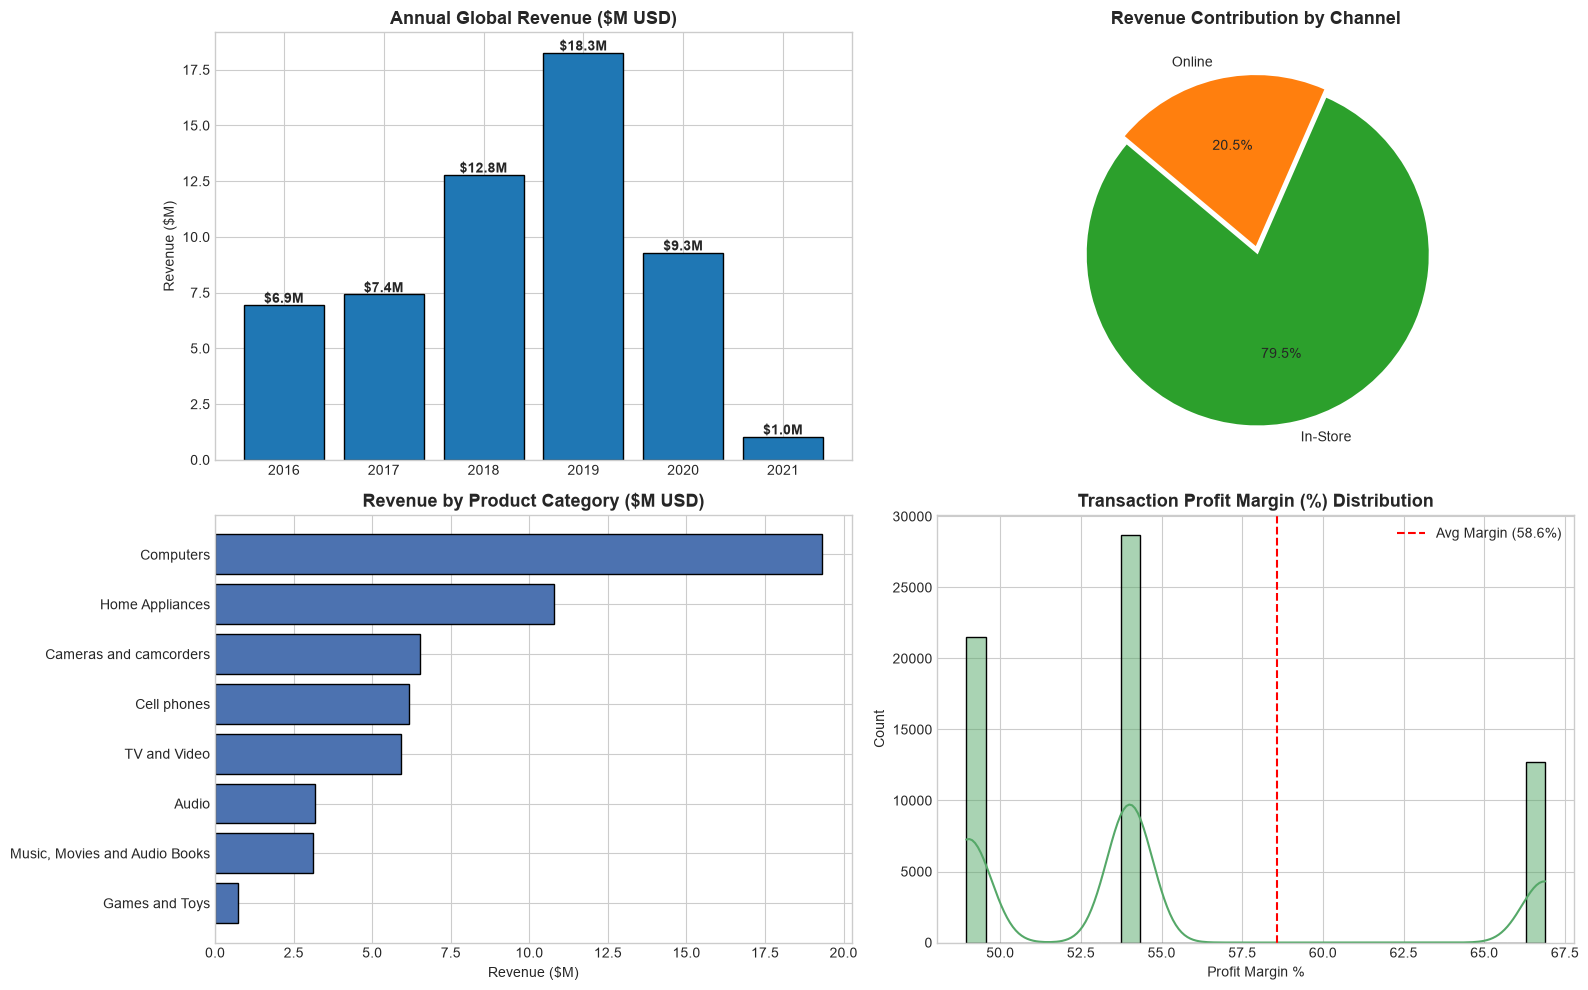

In [12]:
import matplotlib.pyplot as plt
import seaborn as sns

# Set professional visualization style
plt.style.use("seaborn-v0_8-whitegrid")
fig, axes = plt.subplots(2, 2, figsize=(16, 10))

# 1. Annual Revenue Trend
rev_by_year = master.groupby("Order_Year")["Revenue_USD"].sum() / 1e6
axes[0, 0].bar(rev_by_year.index.astype(str), rev_by_year.values, color="#1f77b4", edgecolor="black")
axes[0, 0].set_title("Annual Global Revenue ($M USD)", fontsize=13, fontweight="bold")
axes[0, 0].set_ylabel("Revenue ($M)")
for i, v in enumerate(rev_by_year.values):
    axes[0, 0].text(i, v + 0.1, f"${v:.1f}M", ha="center", fontweight="bold")

# 2. Revenue Share by Channel (Online vs In-Store)
channel_rev = master.groupby("Channel")["Revenue_USD"].sum()
axes[0, 1].pie(channel_rev, labels=channel_rev.index, autopct="%1.1f%%", startangle=140, 
               colors=["#2ca02c", "#ff7f0e"], explode=(0.05, 0))
axes[0, 1].set_title("Revenue Contribution by Channel", fontsize=13, fontweight="bold")

# 3. Top 5 Product Categories by Revenue
cat_rev = (master.groupby("Category")["Revenue_USD"].sum() / 1e6).sort_values(ascending=True)
axes[1, 0].barh(cat_rev.index, cat_rev.values, color="#4c72b0", edgecolor="black")
axes[1, 0].set_title("Revenue by Product Category ($M USD)", fontsize=13, fontweight="bold")
axes[1, 0].set_xlabel("Revenue ($M)")

# 4. Profit Margin Distribution across Transactions
sns.histplot(master["Profit_Margin_Pct"], bins=30, kde=True, ax=axes[1, 1], color="#55a868")
axes[1, 1].axvline(overall_margin, color="red", linestyle="--", label=f"Avg Margin ({overall_margin:.1f}%)")
axes[1, 1].set_title("Transaction Profit Margin (%) Distribution", fontsize=13, fontweight="bold")
axes[1, 1].set_xlabel("Profit Margin %")
axes[1, 1].legend()

plt.tight_layout()
plt.show()